# 03 · Test-set evaluation and comparison with Workshop #1

The test split (6,395 reviews) was scored **once**, after the final model had been chosen
on validation. Workshop #1 baselines are scored on the same frozen split.

Reproduce: `python -m src.evaluate` (this repository) and
`python -m src.baselines --split test` (Workshop #1 repository).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["TQDM_DISABLE"] = "1"  # no progress bars in the rendered notebook
warnings.filterwarnings("ignore", category=UserWarning)

# Notebooks run with notebooks/ as the working directory; make `src` importable.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import plots
from src.config import LABELS, RUNS_DIR

plots.apply_theme()
pd.set_option("display.precision", 4)

In [2]:
evals = {
    "RoBERTa-base (W2, final)": json.loads((RUNS_DIR / "eval_test_model_best.json").read_text()),
    "BERT-base (W2)": json.loads((RUNS_DIR / "eval_test_bert_best.json").read_text()),
}
baselines = json.loads((RUNS_DIR / "workshop1_baselines.json").read_text())

rows = [{"model": name, "workshop": 2, **{k: e[k] for k in ("accuracy", "auc_roc", "macro_f1")}}
        for name, e in evals.items()]
rows += [{"model": f"{name} (W1)", "workshop": 1, **m} for name, m in baselines["test"].items()]
results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
results

,workshop,accuracy,auc_roc,macro_f1
model,,,,
"RoBERTa-base (W2, final)",2,0.8460,0.9357,0.7130
BERT-base (W2),2,0.8394,0.9265,0.6973
Logistic Regression (W1),1,0.7787,0.8879,0.6169
Multinomial Naive Bayes (W1),1,0.8013,0.8286,0.4299
Random Forest (W1),1,0.7962,0.8621,0.3037
Majority class (W1),1,0.7952,0.5000,0.2953


## 1. Headline comparison — test macro-F1 of every model

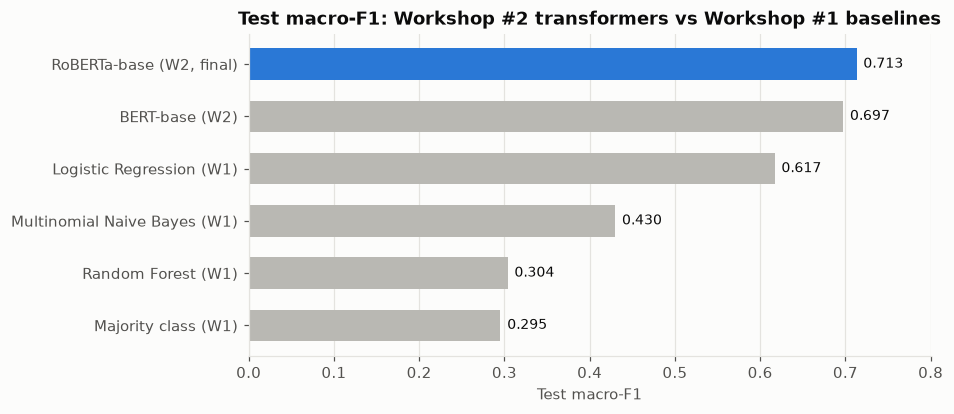

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = results.sort_values("macro_f1")
colors = [plots.SERIES[0] if "final" in name else plots.MUTED for name in order.index]
bars = ax.barh(order.index, order.macro_f1, color=colors, height=0.6)
for bar, value in zip(bars, order.macro_f1):
    ax.text(value + 0.008, bar.get_y() + bar.get_height() / 2, f"{value:.3f}",
            va="center", fontsize=9, color=plots.INK)
ax.set_xlim(0, 0.8)
ax.set_xlabel("Test macro-F1")
ax.set_title("Test macro-F1: Workshop #2 transformers vs Workshop #1 baselines")
ax.grid(axis="y", visible=False)
plots.save(fig, "w2_test_macro_f1_comparison")
plt.show()

In [4]:
best_w1 = results[results.workshop == 1].macro_f1.max()
final = results.loc["RoBERTa-base (W2, final)"]
print(f"RoBERTa vs best Workshop #1 model: {final.macro_f1 - best_w1:+.4f} macro-F1 "
      f"({final.macro_f1 / best_w1 - 1:+.1%} relative)")

RoBERTa vs best Workshop #1 model: +0.0961 macro-F1 (+15.6% relative)


## 2. Validation vs test — RoBERTa-base, BERT-base, Logistic Regression

In [5]:
def best_val(run):
    return json.loads((RUNS_DIR / run / "history.json").read_text())["best_val_macro_f1"]

gap = pd.DataFrame({
    "validation": {"RoBERTa-base": best_val("roberta-base"), "BERT-base": best_val("20261012-183051"),
                   "Logistic Regression (W1)": baselines["validation"]["Logistic Regression"]["macro_f1"]},
    "test": {"RoBERTa-base": evals["RoBERTa-base (W2, final)"]["macro_f1"],
             "BERT-base": evals["BERT-base (W2)"]["macro_f1"],
             "Logistic Regression (W1)": baselines["test"]["Logistic Regression"]["macro_f1"]},
})
gap["difference"] = gap.test - gap.validation
gap

,validation,test,difference
RoBERTa-base,0.7350,0.7130,-0.0220
BERT-base,0.7187,0.6973,-0.0214
Logistic Regression (W1),0.6258,0.6169,-0.0089


## 3. Confusion matrices — RoBERTa-base and BERT-base (test)

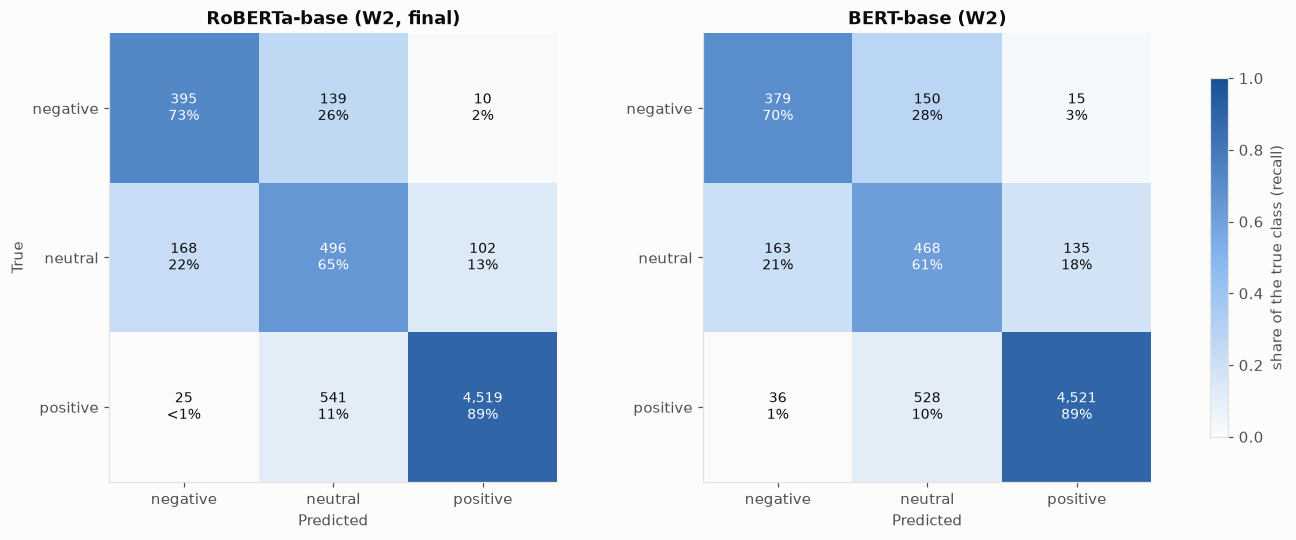

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for index, (ax, (name, e)) in enumerate(zip(axes, evals.items())):
    image = plots.confusion_heatmap(e["confusion"], ax, name, show_ylabel=index == 0)
fig.colorbar(image, ax=axes, shrink=0.8, label="share of the true class (recall)")
plots.save(fig, "w2_test_confusion_matrices")
plt.show()

## 4. Per-class precision, recall and F1 — RoBERTa-base (final model, test)

In [7]:
matrix = np.array(evals["RoBERTa-base (W2, final)"]["confusion"])
precision = matrix.diagonal() / matrix.sum(axis=0)
recall = matrix.diagonal() / matrix.sum(axis=1)
per_class = pd.DataFrame({"support": matrix.sum(axis=1), "precision": precision,
                          "recall": recall, "f1": 2 * precision * recall / (precision + recall)},
                         index=LABELS).rename_axis(columns="RoBERTa-base · test")
per_class

RoBERTa-base · test,support,precision,recall,f1
negative,544,0.6718,0.7261,0.6979
neutral,766,0.4218,0.6475,0.5108
positive,5085,0.9758,0.8887,0.9302


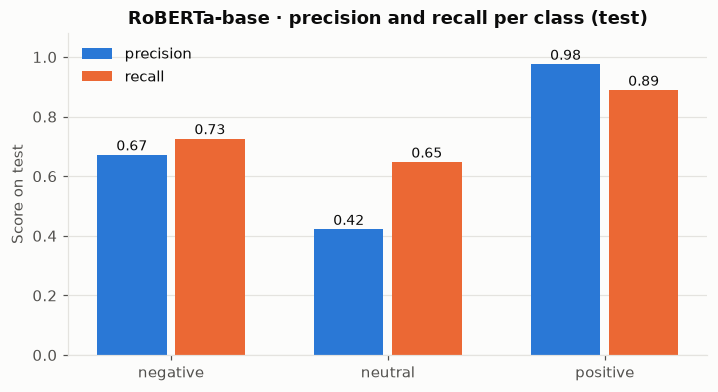

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
width = 0.36
x = np.arange(len(LABELS))
for offset, metric, color in ((-width / 2, "precision", plots.SERIES[0]),
                              (width / 2, "recall", plots.SERIES[1])):
    bars = ax.bar(x + offset, per_class[metric], width - 0.04, color=color, label=metric)
    for bar, value in zip(bars, per_class[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.2f}",
                ha="center", fontsize=9, color=plots.INK)
ax.set_xticks(x, LABELS)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score on test")
ax.set_title("RoBERTa-base · precision and recall per class (test)")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plots.save(fig, "w2_test_precision_recall")
plt.show()

## Findings

- **RoBERTa substantially outperforms Workshop #1**: test macro-F1 **0.713** against
  **0.617** for Logistic Regression (**+0.096**, +15.6 % relative), and it is also best on
  accuracy (0.846) and AUC-ROC (0.936). It is the first model that wins on accuracy *and*
  macro-F1 at once; the Workshop #1 models traded one for the other.
- **The ranking holds on test.** Every model drops from validation to test (transformers
  about −0.02, Logistic Regression −0.009): the validation score of the model *chosen* on
  validation is optimistically biased. The order of the models does not change.
- **Polarity is solved; intensity is not.** RoBERTa-base almost never confuses negative
  and positive (10 negatives called positive, 25 positives called negative, out of 5,629).
  The errors are about *how* positive or negative a review is, i.e. the neutral class.
- **RoBERTa-base, neutral class: recall 0.65 but precision 0.42.** 541 positive reviews (11 % of positives)
  are predicted neutral. This is a direct effect of the balanced class weights
  (neutral 2.78 vs positive 0.42, a 6.6× penalty): the loss makes missing a neutral
  expensive, so the model over-predicts it. Lowering the neutral weight, or tuning the
  decision threshold on validation, would trade some neutral recall for precision.